# Lab 2 — Regression and Cross Validation

Place `CCPP.zip` and `data_02b.csv` beside this notebook. `DATA_DIR` in the first code cell points to that folder independently of the kernel working directory; update it if you move the notebook. Run the cells from the top so imports and helpers are defined. Install `numpy`, `pandas`, `matplotlib`, `scikit-learn`, and `openpyxl` if needed.

## Part A — Multiple Linear Regression

In [6]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.polynomial import Polynomial
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


# Dataset paths do not depend on where the Python kernel starts.
DATA_DIR = Path("D:/CSE-4125-ML/Template/Linear Regression Multivariable")

ITERATIONS = 2000
FEATURES = ["AT", "V", "AP", "RH"]


def mse(actual, predicted):
    return np.mean((actual - predicted) ** 2)


def add_bias(features):
    return np.column_stack((np.ones(len(features)), features))


def gradient_descent(x_train, y_train, x_valid, y_valid, iterations=ITERATIONS):
    train_matrix = add_bias(x_train)
    valid_matrix = add_bias(x_valid)
    weights = np.zeros(train_matrix.shape[1])
    weights[0] = y_train.mean()
    largest_eigenvalue = np.linalg.eigvalsh(train_matrix.T @ train_matrix / len(y_train))[-1]
    learning_rate = 0.9 / largest_eigenvalue
    train_curve = []
    valid_curve = []
    best_error = float("inf")
    best_weights = weights.copy()
    best_iteration = 0
    best_train_error = float("inf")

    for iteration in range(iterations):
        difference = train_matrix @ weights - y_train
        gradient = train_matrix.T @ difference / len(y_train)
        weights -= learning_rate * gradient
        train_error = mse(y_train, train_matrix @ weights)
        valid_error = mse(y_valid, valid_matrix @ weights)
        train_curve.append(train_error)
        valid_curve.append(valid_error)

        if valid_error < best_error:
            best_error = valid_error
            best_train_error = train_error
            best_weights = weights.copy()
            best_iteration = iteration + 1

    return {
        "best_weights": best_weights,
        "final_weights": weights.copy(),
        "train_error": best_train_error,
        "valid_error": best_error,
        "best_iteration": best_iteration,
        "learning_rate": learning_rate,
        "train_curve": train_curve,
        "valid_curve": valid_curve,
    }


def fit_linear(x_train, y_train, x_valid, y_valid, scale=True, iterations=ITERATIONS):
    scaler = StandardScaler() if scale else None

    if scaler is not None:
        x_train = scaler.fit_transform(x_train)
        x_valid = scaler.transform(x_valid)

    result = gradient_descent(x_train, y_train, x_valid, y_valid, iterations)
    result["scaler"] = scaler
    return result


def linear_parameters(model, final=False):
    key = "final_weights" if final else "best_weights"
    weights = model[key]
    scaler = model["scaler"]

    if scaler is None:
        return weights

    coefficients = weights[1:] / scaler.scale_
    intercept = weights[0] - np.sum(coefficients * scaler.mean_)
    return np.r_[intercept, coefficients]


def print_parameters(parameters, names):
    for name, value in zip(names, parameters):
        print(f"{name}: {value:.6f}")


def load_ccpp(path="CCPP.zip"):
    path = DATA_DIR / path
    with ZipFile(path) as archive:
        excel_name = next(name for name in archive.namelist() if name.endswith("Folds5x2_pp.xlsx"))
        data = pd.read_excel(BytesIO(archive.read(excel_name)), sheet_name=0)
    return data


def plot_ccpp_features(data):
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))

    for axis, feature in zip(axes.flat, FEATURES):
        axis.scatter(data[feature], data["PE"], s=5, alpha=0.4)
        axis.set_xlabel(feature)
        axis.set_ylabel("PE")
        axis.set_title(f"{feature} vs PE")

    fig.tight_layout()
    fig.savefig("part_a_features.png", dpi=150)
    plt.show()


def plot_linear_curves(raw_model, scaled_model):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for axis, model, name in zip(axes, [raw_model, scaled_model], ["Without scaling", "With scaling"]):
        axis.plot(model["train_curve"], label="Training MSE")
        axis.plot(model["valid_curve"], label="Validation MSE")
        axis.set_xlabel("Iteration")
        axis.set_ylabel("MSE")
        axis.set_title(name)
        axis.legend()

    fig.tight_layout()
    fig.savefig("part_a_learning_curves.png", dpi=150)
    plt.show()


def part_a(data):
    x = data[FEATURES].to_numpy(dtype=float)
    y = data["PE"].to_numpy(dtype=float)
    x_train, x_valid, y_train, y_valid = train_test_split(x, y, test_size=0.2, random_state=42)

    plot_ccpp_features(data)
    raw_model = fit_linear(x_train, y_train, x_valid, y_valid, scale=False)
    scaled_model = fit_linear(x_train, y_train, x_valid, y_valid, scale=True)
    plot_linear_curves(raw_model, scaled_model)

    for name, model in [("Without scaling", raw_model), ("With scaling", scaled_model)]:
        print(f"\n{name}")
        print(f"Best iteration: {model['best_iteration']}")
        print(f"Learning rate: {model['learning_rate']:.10f}")
        print(f"Training MSE: {model['train_error']:.6f}")
        print(f"Validation MSE: {model['valid_error']:.6f}")
        print_parameters(linear_parameters(model), ["Intercept"] + FEATURES)

    return x_train, x_valid, y_train, y_valid, scaled_model



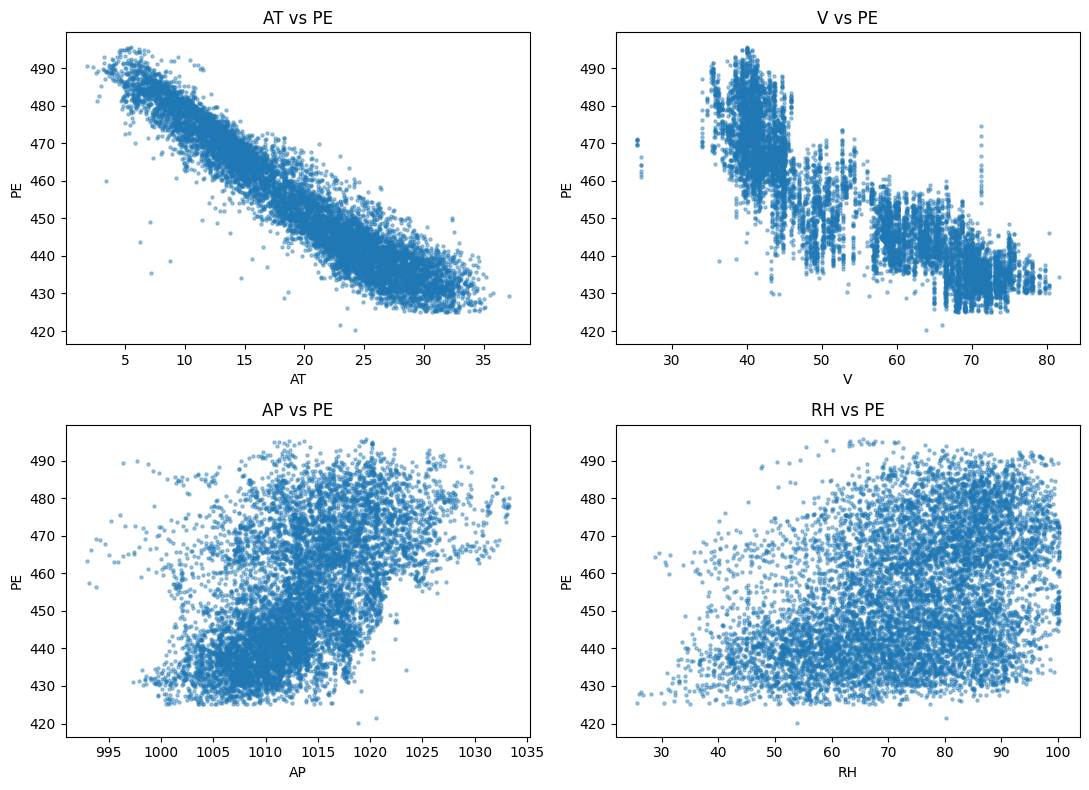

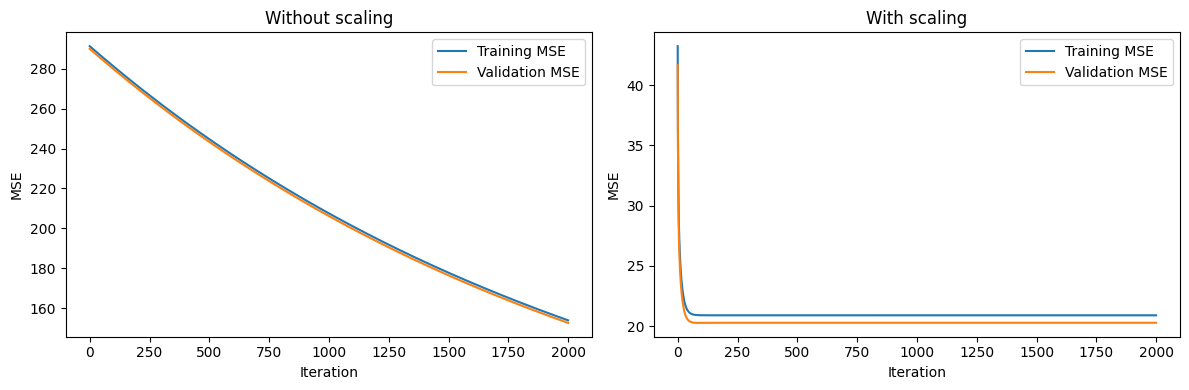


Without scaling
Best iteration: 2000
Learning rate: 0.0000008692
Training MSE: 153.847600
Validation MSE: 152.561741
Intercept: 454.430972
AT: -0.174629
V: -0.271305
AP: 0.009559
RH: 0.115849

With scaling
Best iteration: 90
Learning rate: 0.3688679641
Training MSE: 20.903570
Validation MSE: 20.263773
Intercept: 446.737798
AT: -1.953382
V: -0.246207
AP: 0.069662
RH: -0.152697


In [7]:
data = load_ccpp()
x_train, x_valid, y_train, y_valid, model = part_a(data)


## Part B — Five-Fold Cross Validation

In [8]:
def part_b(x_train, x_valid, y_train, y_valid, previous_model):
    splitter = KFold(n_splits=5, shuffle=True, random_state=42)
    fold_errors = []
    fold_iterations = []
    fold_parameters = []

    for number, (train_idx, valid_idx) in enumerate(splitter.split(x_train), start=1):
        model = fit_linear(
            x_train[train_idx], y_train[train_idx],
            x_train[valid_idx], y_train[valid_idx]
        )
        fold_errors.append(model["valid_error"])
        fold_iterations.append(model["best_iteration"])
        fold_parameters.append(linear_parameters(model))
        print(f"Fold {number}: validation MSE = {model['valid_error']:.6f}, best iteration = {model['best_iteration']}")

    chosen_iterations = int(np.median(fold_iterations))
    final_model = fit_linear(x_train, y_train, x_valid, y_valid, iterations=chosen_iterations)
    final_weights = final_model["final_weights"]
    scaled_train = final_model["scaler"].transform(x_train)
    scaled_valid = final_model["scaler"].transform(x_valid)
    final_train_error = mse(y_train, add_bias(scaled_train) @ final_weights)
    final_valid_error = mse(y_valid, add_bias(scaled_valid) @ final_weights)

    print(f"\nMean 5-fold validation MSE: {np.mean(fold_errors):.6f}")
    print(f"Standard deviation: {np.std(fold_errors):.6f}")
    print(f"Chosen training iterations: {chosen_iterations}")
    print(f"Refitted model training MSE: {final_train_error:.6f}")
    print(f"Refitted model holdout MSE: {final_valid_error:.6f}")
    print("\nBest individual fold parameters:")
    print_parameters(fold_parameters[int(np.argmin(fold_errors))], ["Intercept"] + FEATURES)

    comparison = pd.DataFrame({
        "Parameter": ["Intercept"] + FEATURES,
        "Part A": linear_parameters(previous_model),
        "Part B refitted": linear_parameters(final_model, final=True),
    })
    print("\nParameter comparison in original feature units:")
    print(comparison.to_string(index=False))



In [9]:
part_b(x_train, x_valid, y_train, y_valid, model)


Fold 1: validation MSE = 22.330339, best iteration = 119
Fold 2: validation MSE = 20.853533, best iteration = 96
Fold 3: validation MSE = 20.397574, best iteration = 95
Fold 4: validation MSE = 20.699404, best iteration = 827
Fold 5: validation MSE = 20.256579, best iteration = 855

Mean 5-fold validation MSE: 20.907486
Standard deviation: 0.742214
Chosen training iterations: 119
Refitted model training MSE: 20.894486
Refitted model holdout MSE: 20.268233

Best individual fold parameters:
Intercept: 447.819369
AT: -1.978255
V: -0.233840
AP: 0.068692
RH: -0.156181

Parameter comparison in original feature units:
Parameter     Part A  Part B refitted
Intercept 446.737798       452.016764
       AT  -1.953382        -1.975302
        V  -0.246207        -0.236693
       AP   0.069662         0.064632
       RH  -0.152697        -0.156351


## Part C — Polynomial Regression

In [10]:
def load_polynomial_data(path="data_02b.csv"):
    path = DATA_DIR / path
    data = pd.read_csv(path)
    numeric_header = pd.to_numeric(pd.Index(data.columns), errors="coerce").notna().all()

    if numeric_header:
        data = pd.read_csv(path, header=None)

    if data.shape[1] != 2:
        raise ValueError("data_02b.csv must have exactly two columns: feature and target")

    values = data.apply(pd.to_numeric).to_numpy(dtype=float)
    return values[:, :1], values[:, 1]


def fit_polynomial(x_train, y_train, x_valid, y_valid, degree):
    scaler = StandardScaler()
    polynomial = PolynomialFeatures(degree=degree, include_bias=False)
    train_features = polynomial.fit_transform(scaler.fit_transform(x_train))
    valid_features = polynomial.transform(scaler.transform(x_valid))
    result = gradient_descent(train_features, y_train, valid_features, y_valid)
    result["scaler"] = scaler
    result["polynomial"] = polynomial
    return result


def polynomial_predict(model, x):
    transformed = model["polynomial"].transform(model["scaler"].transform(x))
    return add_bias(transformed) @ model["best_weights"]


def polynomial_parameters(model):
    scaler = model["scaler"]
    standardized_x = Polynomial([-scaler.mean_[0] / scaler.scale_[0], 1 / scaler.scale_[0]])
    return Polynomial(model["best_weights"])(standardized_x).coef


def plot_polynomial_results(x, y, models):
    x_line = np.linspace(x.min(), x.max(), 300).reshape(-1, 1)
    plt.figure(figsize=(9, 5))
    plt.scatter(x[:, 0], y, s=12, alpha=0.5, label="Data")

    for degree, model in models.items():
        plt.plot(x_line[:, 0], polynomial_predict(model, x_line), label=f"Degree {degree}")

    plt.xlabel("Feature")
    plt.ylabel("Target")
    plt.title("Polynomial regression")
    plt.legend()
    plt.tight_layout()
    plt.savefig("part_c_fitted_curves.png", dpi=150)
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.bar([str(degree) for degree in models], [model["valid_error"] for model in models.values()])
    plt.xlabel("Polynomial degree")
    plt.ylabel("Best validation MSE")
    plt.title("Validation error comparison")
    plt.tight_layout()
    plt.savefig("part_c_validation_errors.png", dpi=150)
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    for axis, (degree, model) in zip(axes, models.items()):
        axis.plot(model["train_curve"], label="Training MSE")
        axis.plot(model["valid_curve"], label="Validation MSE")
        axis.set_xlabel("Iteration")
        axis.set_ylabel("MSE")
        axis.set_title(f"Degree {degree}")
        axis.legend()

    fig.tight_layout()
    fig.savefig("part_c_learning_curves.png", dpi=150)
    plt.show()


def part_c(path="data_02b.csv"):
    x, y = load_polynomial_data(path)
    x_train, x_valid, y_train, y_valid = train_test_split(x, y, test_size=0.2, random_state=42)
    models = {degree: fit_polynomial(x_train, y_train, x_valid, y_valid, degree) for degree in (1, 2, 3)}
    plot_polynomial_results(x, y, models)

    for degree, model in models.items():
        print(f"Degree {degree}: training MSE = {model['train_error']:.6f}, validation MSE = {model['valid_error']:.6f}")

    best_degree = min(models, key=lambda degree: models[degree]["valid_error"])
    best_model = models[best_degree]
    print(f"\nBest degree: {best_degree}")
    print(f"Best iteration: {best_model['best_iteration']}")
    print(f"Training MSE: {best_model['train_error']:.6f}")
    print(f"Validation MSE: {best_model['valid_error']:.6f}")
    print("Coefficients in original feature units:")
    print_parameters(polynomial_parameters(best_model), [f"Coefficient of x^{i}" for i in range(best_degree + 1)])



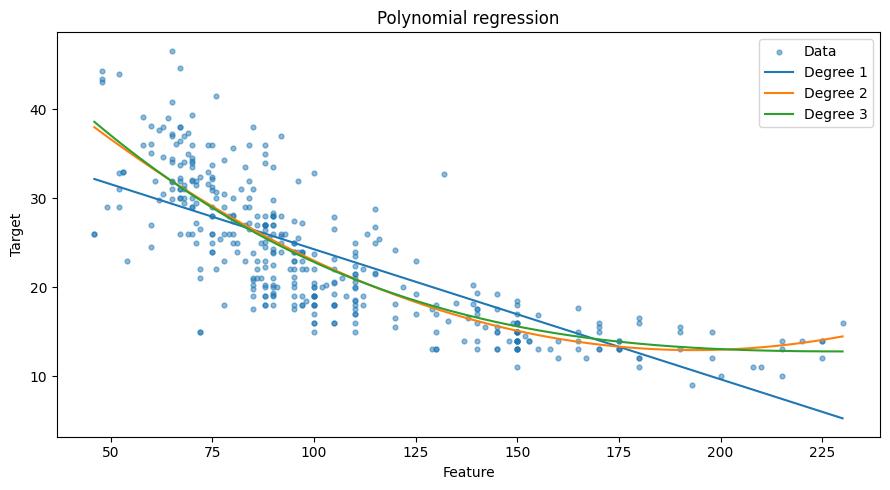

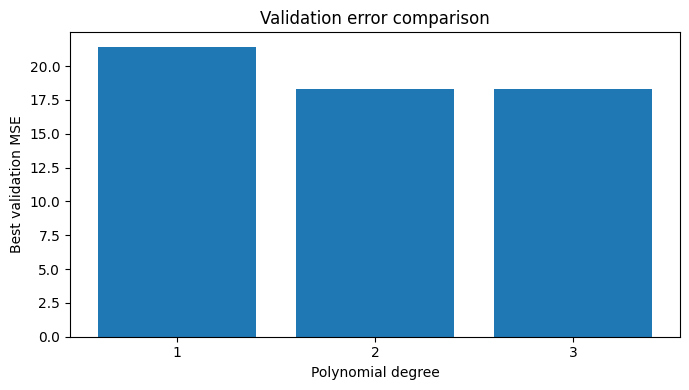

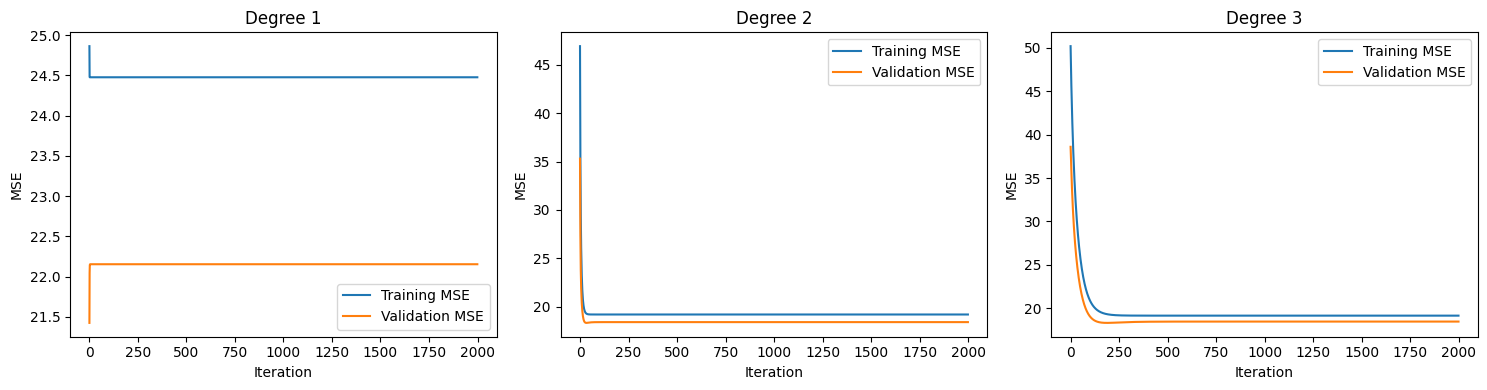

Degree 1: training MSE = 24.861414, validation MSE = 21.424804
Degree 2: training MSE = 19.293249, validation MSE = 18.337718
Degree 3: training MSE = 19.310852, validation MSE = 18.308675

Best degree: 3
Best iteration: 189
Training MSE: 19.310852
Validation MSE: 18.308675
Coefficients in original feature units:
Coefficient of x^0: 60.717758
Coefficient of x^1: -0.581788
Coefficient of x^2: 0.002341
Coefficient of x^3: -0.000003


In [11]:
csv_path = "data_02b.csv"
part_c(csv_path)
